Dataset processado não encontrado. Buscando o dataset bruto para tratar agora...
Dataset bruto encontrado em: /workspaces/Projetos/Projeto Churn/Projeto Churn/data - arq de dados/Telco-Customer-Churn.csv. Aplicando limpeza...
Dataset limpo gerado e salvo com sucesso em data/processed/churn_processed.csv!

Treinando o modelo Random Forest...

=== Matriz de Confusão ===
[[924 111]
 [190 184]]

=== Relatório de Classificação ===
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.77      0.79      0.78      1409

ROC-AUC Score: 0.8251

Modelo treinado salvo com sucesso em: models/random_forest_churn.pkl
Base analítica para o Power BI salva com sucesso em: data/processed/churn_para_powerbi.csv


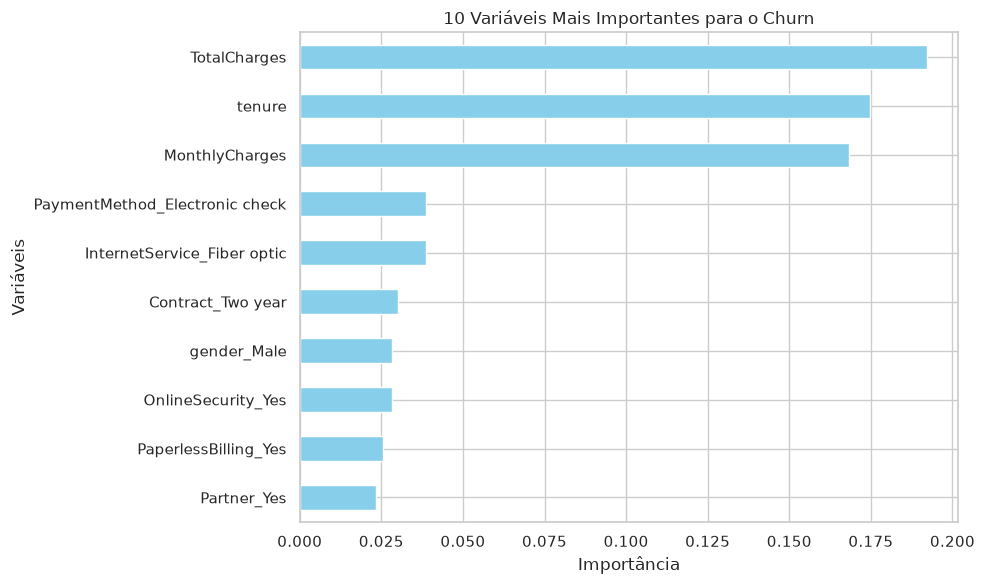

In [4]:
import os
import glob
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import joblib

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# 1. Tenta encontrar o arquivo processado. Se não achar, processa o arquivo bruto automaticamente.
arquivos_proc = glob.glob("**/churn_processed.csv", recursive=True) + glob.glob("/workspaces/**/churn_processed.csv", recursive=True)

if arquivos_proc:
    caminho_csv = arquivos_proc[0]
    print(f"Sucesso! Dataset processado encontrado em: {caminho_csv}")
    df = pd.read_csv(caminho_csv)
else:
    print("Dataset processado não encontrado. Buscando o dataset bruto para tratar agora...")
    arquivos_raw = glob.glob("**/*Telco*.csv*", recursive=True) + glob.glob("/workspaces/**/*Telco*.csv*", recursive=True)
    arquivos_raw = [f for f in arquivos_raw if 'processed' not in f and 'checkpoint' not in f]
    
    if not arquivos_raw:
        raise FileNotFoundError("Nenhum arquivo do Telco Churn foi encontrado. Certifique-se de que o arquivo CSV do Kaggle está na pasta do projeto.")
    
    caminho_raw = arquivos_raw[0]
    print(f"Dataset bruto encontrado em: {caminho_raw}. Aplicando limpeza...")
    df = pd.read_csv(caminho_raw)
    
    # Limpeza rápida dos dados brutos
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
    df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
    if 'customerID' in df.columns:
        df = df.drop(columns=['customerID'])
    df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
    
    # Salva o arquivo processado para as próximas etapas
    os.makedirs('data/processed', exist_ok=True)
    df.to_csv('data/processed/churn_processed.csv', index=False)
    print("Dataset limpo gerado e salvo com sucesso em data/processed/churn_processed.csv!")

if "Churn" not in df.columns:
    raise ValueError("A coluna 'Churn' não existe no dataset.")

# 2. Preparação e Codificação (Encoding)
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)
y = df["Churn"]

# 3. Divisão de Treino e Teste (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Treinamento do Modelo (Random Forest)
print("\nTreinando o modelo Random Forest...")
modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

# 5. Avaliação
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print("\n=== Matriz de Confusão ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== Relatório de Classificação ===")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# 6. Salvar o modelo treinado (Artefato .pkl)
os.makedirs('models', exist_ok=True)
joblib.dump(modelo, 'models/random_forest_churn.pkl')
print("\nModelo treinado salvo com sucesso em: models/random_forest_churn.pkl")

# 7. Enriquecer o DataFrame com as previsões para o Power BI
df['Probabilidade_Churn'] = modelo.predict_proba(X)[:, 1]
df['Previsao_Churn'] = modelo.predict(X)

caminho_bi = 'data/processed/churn_para_powerbi.csv'
df.to_csv(caminho_bi, index=False)
print(f"Base analítica para o Power BI salva com sucesso em: {caminho_bi}")

# 8. Gráfico de Importância das Variáveis
importancia = pd.Series(modelo.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importancia.head(10).sort_values().plot(kind="barh", color="skyblue")
plt.title("10 Variáveis Mais Importantes para o Churn")
plt.xlabel("Importância")
plt.ylabel("Variáveis")
plt.tight_layout()
plt.show()